## WorldTrace Unusual NYC Trajectories (Flag 3)

### Dataset Overview
A point-level derived WorldTrace case containing 24 car trajectories: 21 ordinary urban comparison trajectories and three explicitly named deviations. The CSV exposes coordinates, timestamps, point-level speed, average speed, and traveled distance.

The notebook exposes the primary analysis table.

Goal: Investigate the most unusual trajectories in the provided NYC data and explain how they differ from the dominant patterns in the collection.

Role: NYC mobility insight analyst


Category: Unusual Trajectories

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "03_unusual_trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

### **Question 1**: Which trajectories differ from the dominant pattern in average speed or traveled distance?

#### Analysis action

Use the speed plot to identify wt03_trajectory_22 and wt03_trajectory_23 and the distance plot to identify wt03_trajectory_24 before examining their route geometry.

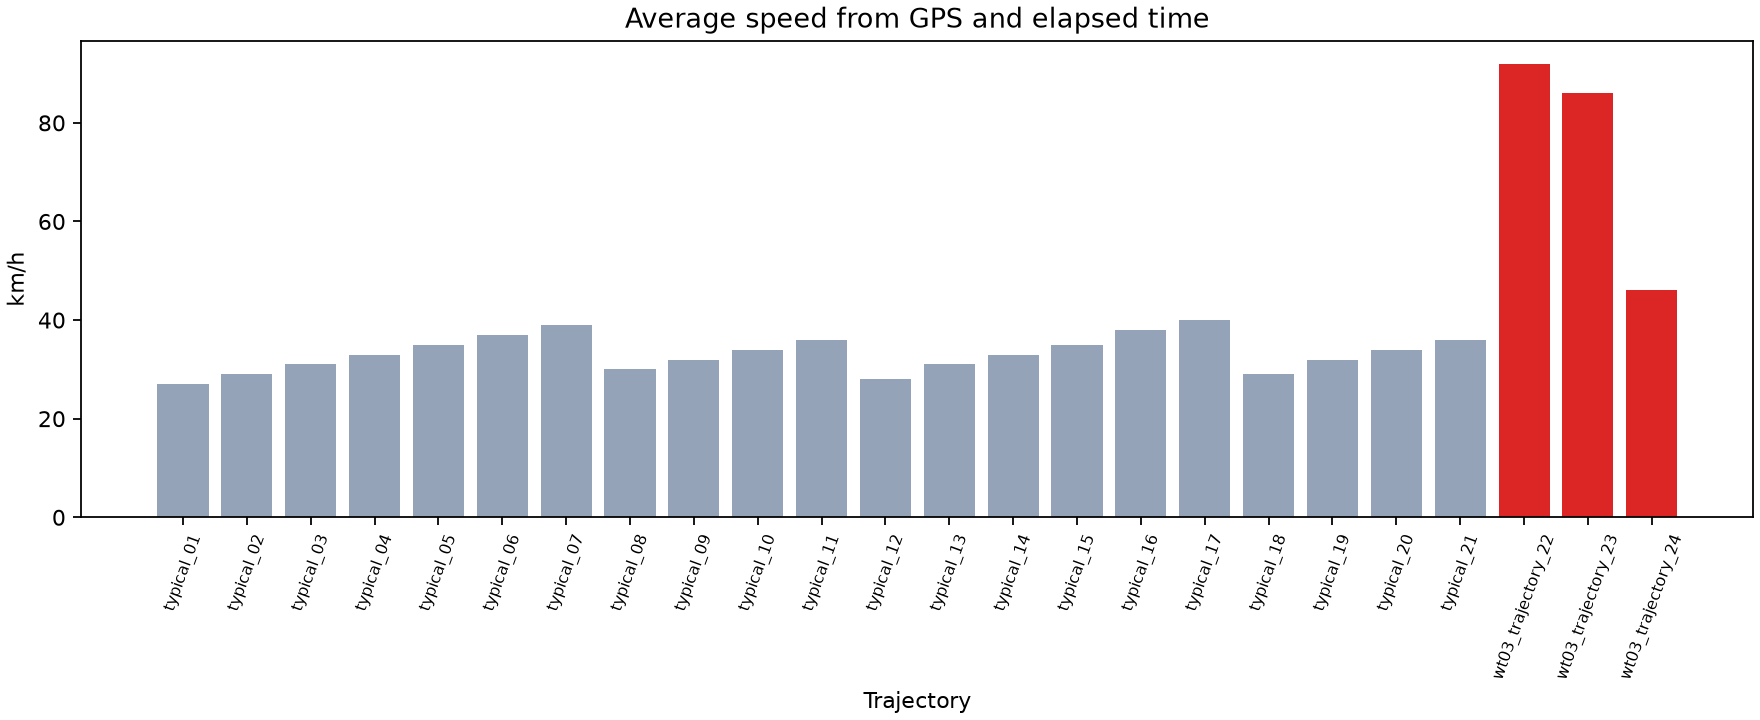

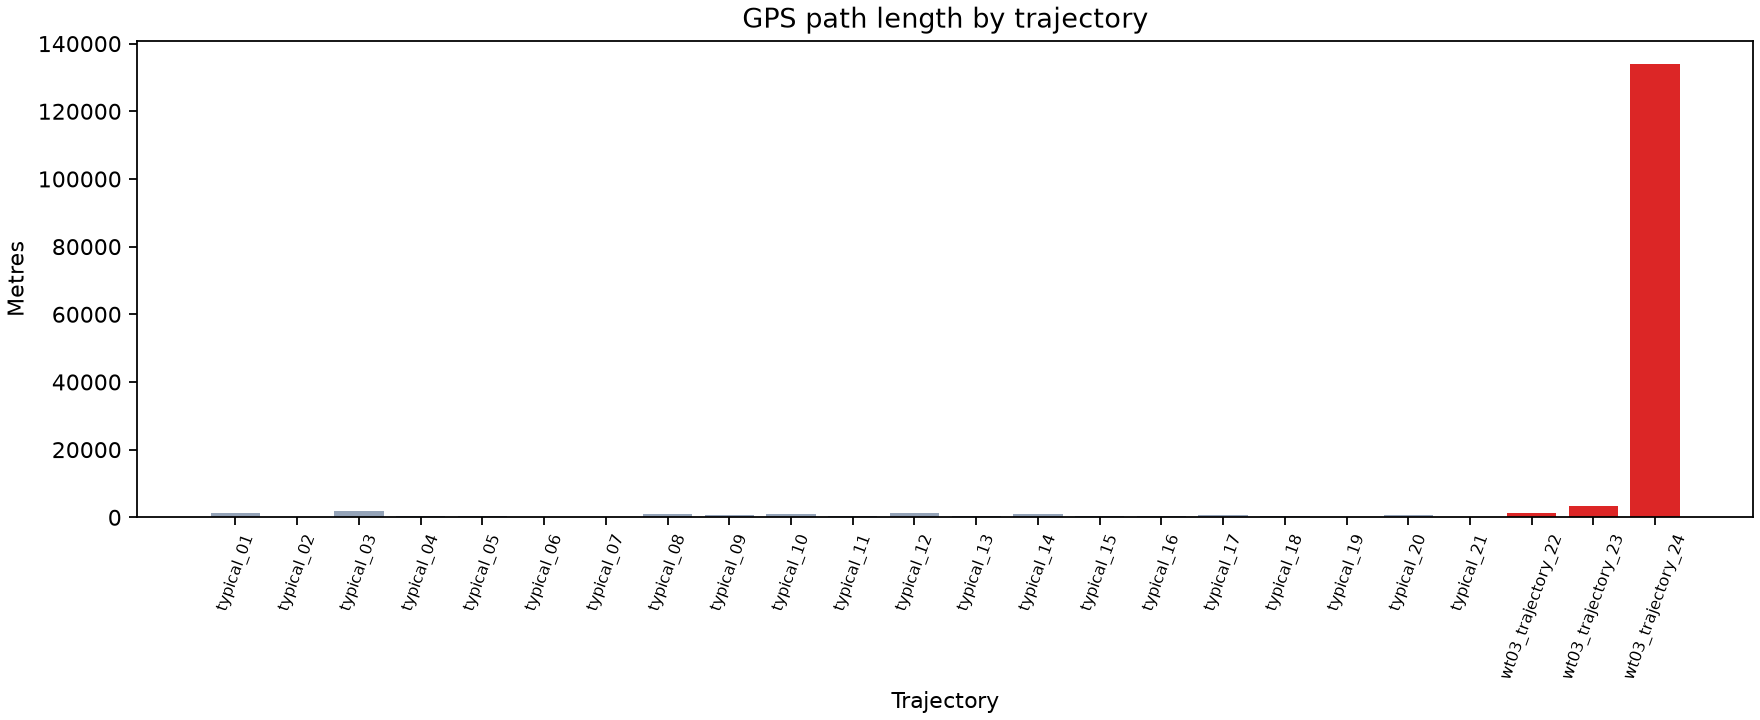

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv(dataset_path)
derived=[]
for tid,g in df.groupby('trajectory_id'):
    g=g.sort_values('point_index');x=np.radians(g.longitude.to_numpy());y=np.radians(g.latitude.to_numpy())
    a=np.sin(np.diff(y)/2)**2+np.cos(y[:-1])*np.cos(y[1:])*np.sin(np.diff(x)/2)**2
    km=6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))
    seconds=pd.to_datetime(g.timestamp,format='mixed').diff().dt.total_seconds().to_numpy()[1:]
    derived.append({'trajectory_id':tid,'distance_meters':float(km.sum()*1000),'avg_speed_kmh':float(km.sum()/seconds.sum()*3600)})
summary=pd.DataFrame(derived)
print(summary.sort_values('avg_speed_kmh',ascending=False))

from IPython.display import Image, display
display(Image(filename='visualizations/speed_overview.png'))
display(Image(filename='visualizations/distance_overview.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "wt03_trajectory_22 and wt03_trajectory_23 differ from the typical patterns: their average speeds are much higher, while wt03_trajectory_24 differs from the others because the traveled distance is the longest and much longer than the others.",
  "insight_value": {
    "trajectory_count": 24,
    "dominant_pattern": "ordinary urban car trajectories",
    "speed_exceptions": [
      "wt03_trajectory_22",
      "wt03_trajectory_23"
    ],
    "distance_exception": "wt03_trajectory_24"
  },
  "plot": {
    "plot_type": "two_plots",
    "title": "Speed and Distance Exceptions",
    "files": [
      "visualizations/speed_overview.png",
      "visualizations/distance_overview.png"
    ],
    "description": "Separate plots show that wt03_trajectory_22 and wt03_trajectory_23 are speed exceptions and wt03_trajectory_24 is the distance exception relative to 21 ordinary comparison trajectories."
  },
  "question": "Which trajectories differ from the dominant pattern in average speed or traveled distance?",
  "actionable_insight": "Use the speed plot to identify wt03_trajectory_22 and wt03_trajectory_23 and the distance plot to identify wt03_trajectory_24 before examining their route geometry.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\ndf=pd.read_csv(dataset_path)\nderived=[]\nfor tid,g in df.groupby('trajectory_id'):\n    g=g.sort_values('point_index');x=np.radians(g.longitude.to_numpy());y=np.radians(g.latitude.to_numpy())\n    a=np.sin(np.diff(y)/2)**2+np.cos(y[:-1])*np.cos(y[1:])*np.sin(np.diff(x)/2)**2\n    km=6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))\n    seconds=pd.to_datetime(g.timestamp,format='mixed').diff().dt.total_seconds().to_numpy()[1:]\n    derived.append({'trajectory_id':tid,'distance_meters':float(km.sum()*1000),'avg_speed_kmh':float(km.sum()/seconds.sum()*3600)})\nsummary=pd.DataFrame(derived)\nprint(summary.sort_values('avg_speed_kmh',ascending=False))\n",
  "insight_type": "exception_deviation",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: Do wt03_trajectory_22 and wt03_trajectory_23 combine similarly high speeds with the same broad start and destination areas despite following different road corridors?

#### Analysis action

The route and speed comparison separates high speed from route geometry: wt03_trajectory_22 and wt03_trajectory_23 share broad endpoints but not the same road path or point-level speed profile.

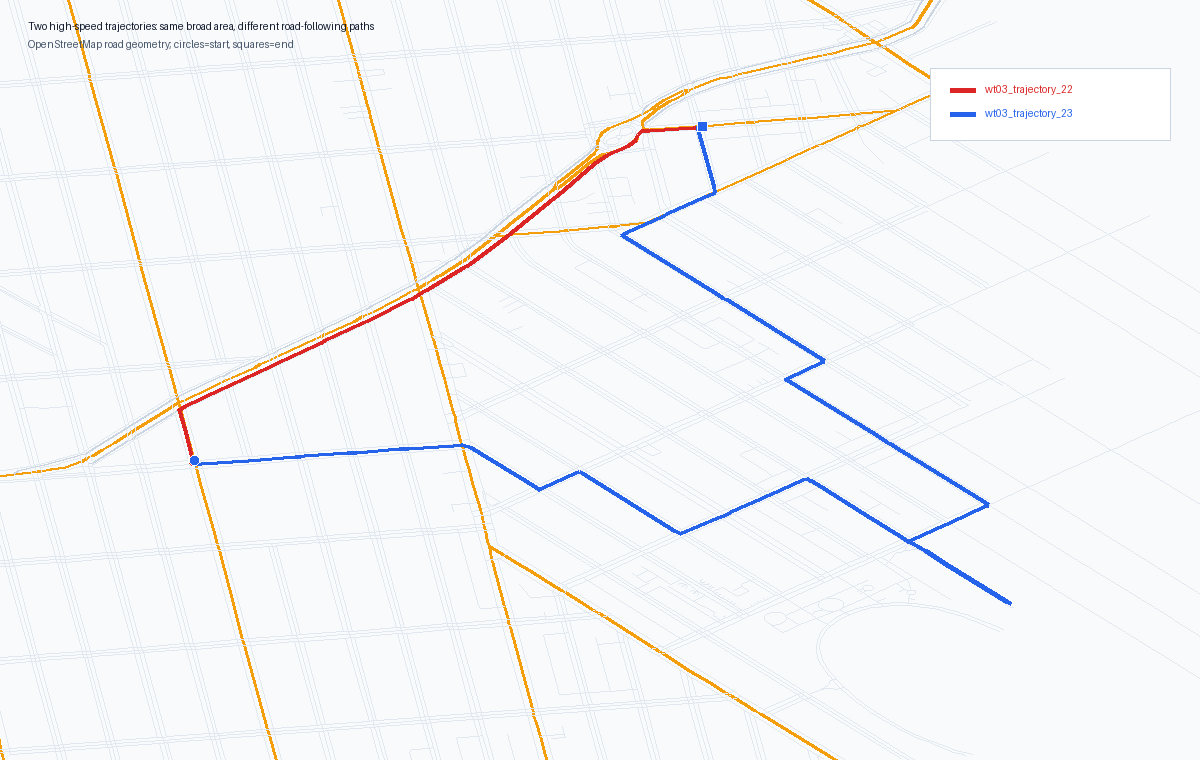

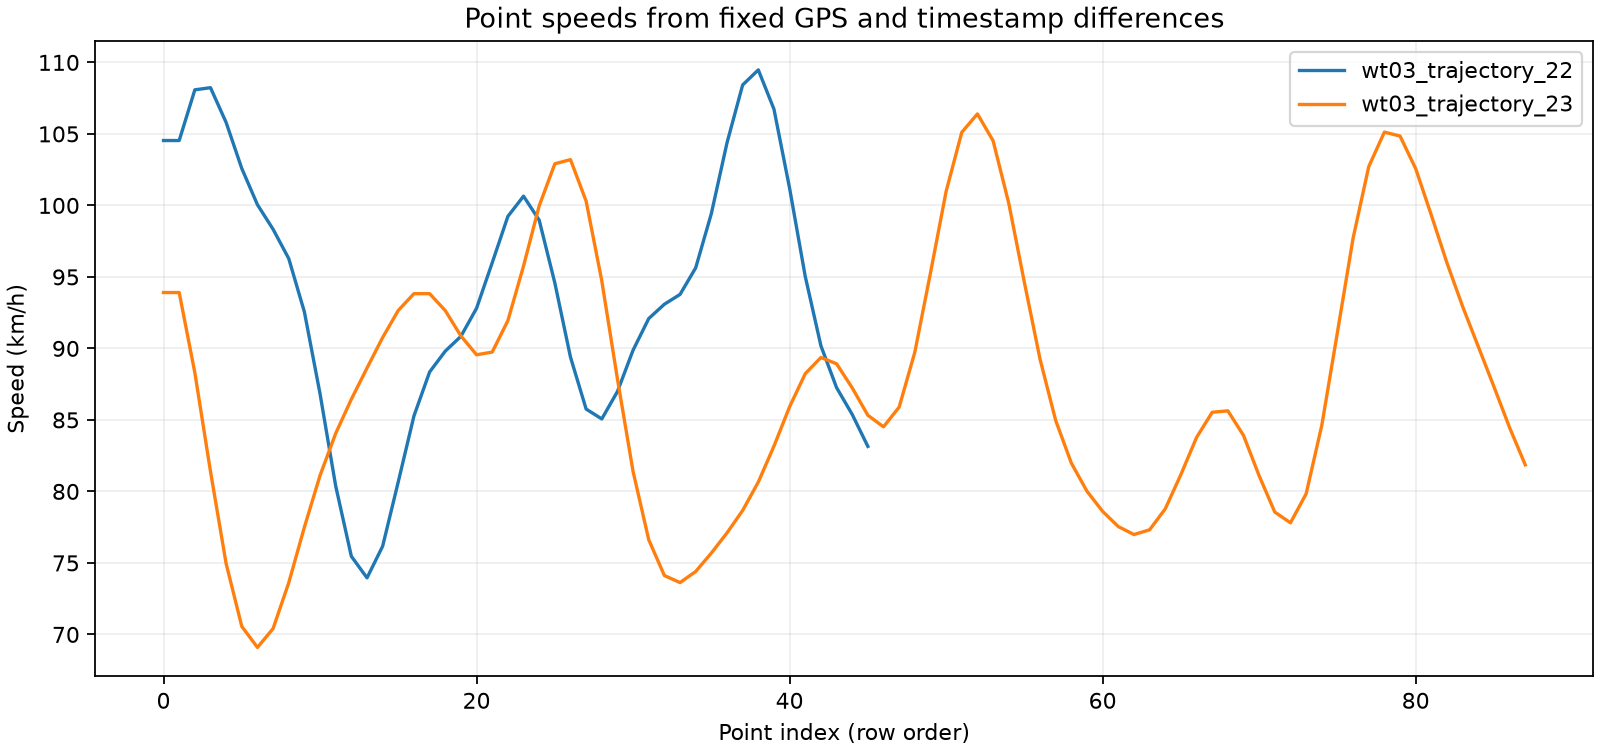

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv(dataset_path)
derived=[]
for tid,g in df.groupby('trajectory_id'):
    g=g.sort_values('point_index');x=np.radians(g.longitude.to_numpy());y=np.radians(g.latitude.to_numpy())
    a=np.sin(np.diff(y)/2)**2+np.cos(y[:-1])*np.cos(y[1:])*np.sin(np.diff(x)/2)**2
    km=6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))
    seconds=pd.to_datetime(g.timestamp,format='mixed').diff().dt.total_seconds().to_numpy()[1:]
    derived.append({'trajectory_id':tid,'distance_meters':float(km.sum()*1000),'avg_speed_kmh':float(km.sum()/seconds.sum()*3600)})
summary=pd.DataFrame(derived)
print(summary[summary.trajectory_id.isin(['wt03_trajectory_22','wt03_trajectory_23'])]); print(df.groupby('trajectory_id')[['start_region','end_region']].first())

from IPython.display import Image, display
display(Image(filename='visualizations/ab_route_map.png'))
display(Image(filename='visualizations/ab_speed.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_diagnostic",
  "insight": "wt03_trajectory_22 and wt03_trajectory_23 have average speeds over 80 km/h, start from the same broad South Brooklyn area, and end in the same broad South Brooklyn destination area, but their observed road-following trajectories are very different.",
  "insight_value": {
    "trajectories": [
      "wt03_trajectory_22",
      "wt03_trajectory_23"
    ],
    "speed_threshold_kmh": 80,
    "start_area": "South Brooklyn",
    "destination_area": "South Brooklyn"
  },
  "plot": {
    "plot_type": "map_and_speed_plot",
    "title": "Road-Following Route and Speed Comparison",
    "files": [
      "visualizations/ab_route_map.png",
      "visualizations/ab_speed.png"
    ],
    "description": "Fixed road-following GPS paths and point speeds computed from adjacent GPS distances and timestamp differences; average speeds use total GPS path length / elapsed time. Region strings are descriptive labels."
  },
  "question": "Do wt03_trajectory_22 and wt03_trajectory_23 combine similarly high speeds with the same broad start and destination areas despite following different road corridors?",
  "actionable_insight": "The route and speed comparison separates high speed from route geometry: wt03_trajectory_22 and wt03_trajectory_23 share broad endpoints but not the same road path or point-level speed profile.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\ndf=pd.read_csv(dataset_path)\nderived=[]\nfor tid,g in df.groupby('trajectory_id'):\n    g=g.sort_values('point_index');x=np.radians(g.longitude.to_numpy());y=np.radians(g.latitude.to_numpy())\n    a=np.sin(np.diff(y)/2)**2+np.cos(y[:-1])*np.cos(y[1:])*np.sin(np.diff(x)/2)**2\n    km=6371.0088*2*np.arcsin(np.sqrt(np.clip(a,0,1)))\n    seconds=pd.to_datetime(g.timestamp,format='mixed').diff().dt.total_seconds().to_numpy()[1:]\n    derived.append({'trajectory_id':tid,'distance_meters':float(km.sum()*1000),'avg_speed_kmh':float(km.sum()/seconds.sum()*3600)})\nsummary=pd.DataFrame(derived)\nprint(summary[summary.trajectory_id.isin(['wt03_trajectory_22','wt03_trajectory_23'])]); print(df.groupby('trajectory_id')[['start_region','end_region']].first())\n",
  "insight_type": "exception_deviation",
  "evidence": "Both average and point-wise speed derive from GPS and timestamps. point_index only orders rows; region labels do not add native inputs.",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Does wt03_trajectory_24 avoid the NYC urban core, and how is that route related to its unusually long traveled distance?

#### Analysis action

The map links wt03_trajectory_24's unusual distance to its geographic extent outside the urban core rather than to a short local detour.

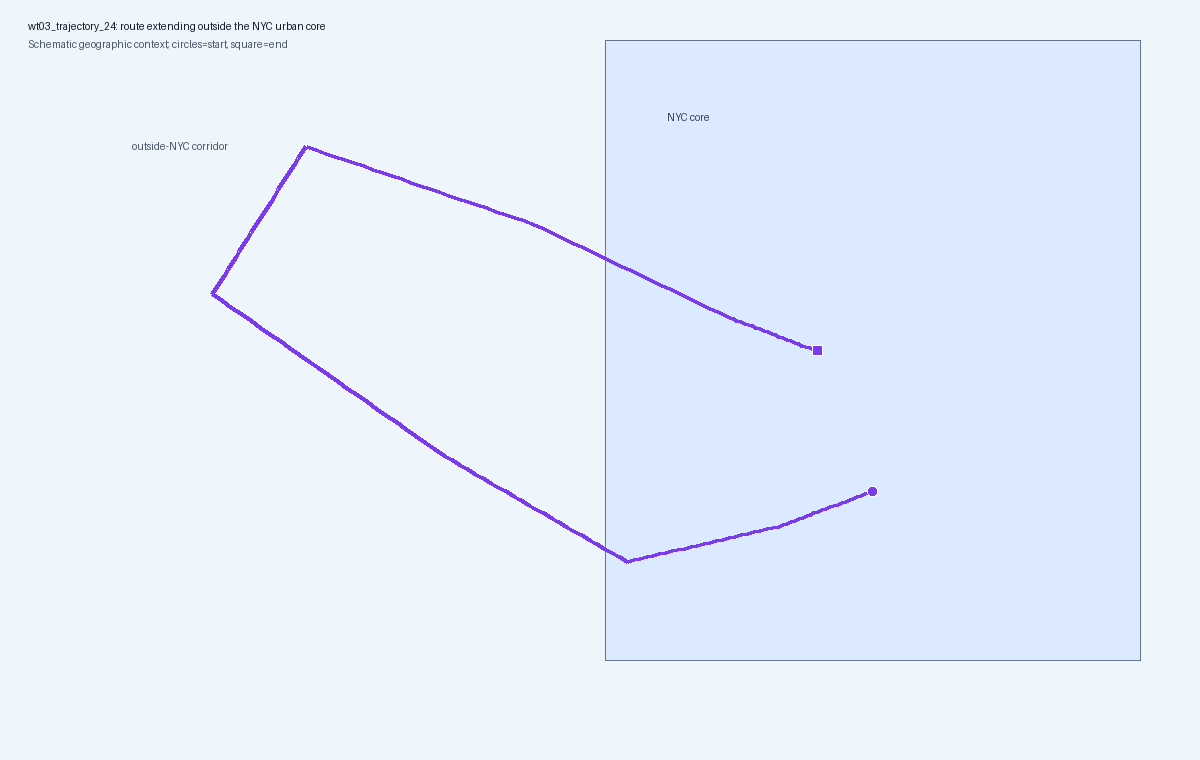

In [ ]:
import matplotlib.pyplot as plt
trip = df[df['trajectory_id'] == 'wt03_trajectory_24'].sort_values('point_index')
plt.plot(trip['longitude'], trip['latitude'], color='purple')
plt.scatter([trip['longitude'].iloc[0], trip['longitude'].iloc[-1]], [trip['latitude'].iloc[0], trip['latitude'].iloc[-1]])
plt.title('wt03_trajectory_24 outside-city route')
plt.xlabel('Longitude'); plt.ylabel('Latitude')
plt.tight_layout()
from IPython.display import Image, display
display(Image(filename='visualizations/c_outside_city_map.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_diagnostic",
  "insight": "wt03_trajectory_24 avoids the NYC urban core for most of its route, which leads to its longest traveled distance while its start and end remain in the city.",
  "insight_value": {
    "trajectory": "wt03_trajectory_24",
    "route_extent": "outside NYC core",
    "distance_rank": 1
  },
  "plot": {
    "plot_type": "map",
    "title": "wt03_trajectory_24 Outside-City Route",
    "files": [
      "visualizations/c_outside_city_map.png"
    ],
    "description": "The map shows wt03_trajectory_24 leaving the NYC core and returning to a city endpoint."
  },
  "question": "Does wt03_trajectory_24 avoid the NYC urban core, and how is that route related to its unusually long traveled distance?",
  "actionable_insight": "The map links wt03_trajectory_24's unusual distance to its geographic extent outside the urban core rather than to a short local detour.",
  "code": "import matplotlib.pyplot as plt\ntrip = df[df['trajectory_id'] == 'wt03_trajectory_24'].sort_values('point_index')\nplt.plot(trip['longitude'], trip['latitude'], color='purple')\nplt.scatter([trip['longitude'].iloc[0], trip['longitude'].iloc[-1]], [trip['latitude'].iloc[0], trip['latitude'].iloc[-1]])\nplt.title('wt03_trajectory_24 outside-city route')\nplt.xlabel('Longitude'); plt.ylabel('Latitude')\nplt.tight_layout()",
  "insight_type": "exception_deviation",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 3)

wt03_trajectory_22 and wt03_trajectory_23 differ from the typical patterns: their average speeds are much higher, while wt03_trajectory_24 differs from the others because the traveled distance is the longest and much longer than the others. wt03_trajectory_22 and wt03_trajectory_23 have average speeds over 80 km/h, start from the same broad South Brooklyn area, and end in the same broad South Brooklyn destination area, but their observed road-following trajectories are very different. wt03_trajectory_24 avoids the NYC urban core for most of its route, which leads to its longest traveled distance while its start and end remain in the city.
